# STATS 425 · Week 7 lab
**Learning from preferences**  
**TA:** Ali Kaazempur-Mofrad

In Weeks 4–6, a verifier scored every response: in Weeks 4 and 5 it checked whether the answer was correct, and in Week 6 the reward also scored the reported confidence. Many tasks have no verifier. No program can check whether an explanation is helpful or a reply has the right tone. People can, however, **compare two responses and say which one they prefer**. Today, we learn from such pairwise preferences: we model them with the Bradley–Terry model, fit a **reward model**, compute the policy that maximizes that reward while staying close to a reference policy (the idea behind **reinforcement learning from human feedback, RLHF**), and then train a policy directly on the preferences with **direct preference optimization (DPO)**.

**A transparent setup.** Instead of writing text, we describe each candidate response by four numbers between 0 and 1: relevance, accuracy, verbosity (length), and politeness. Simulated annotators compare responses using a hidden score that we choose, so we can check how well each method recovers what they value. For each prompt, the policy chooses among four candidate responses, much as Week 4's policy chose among three answers.

| Section | Question we answer |
|---|---|
| 1. From comparisons to scores | How can noisy pairwise choices reveal a hidden score? |
| 2. Fitting a reward model | How do we estimate that score from comparisons? |
| 3. Turning a reward into a policy | Which policy best trades reward against staying close to a reference? |
| 4. Direct preference optimization | Can we train the policy on preferences without a separate reward model? |
| 5. Experiments: β, noise, and biased annotators | What changes when we vary β or the annotators? |

**Set up the notebook.** Use a standard Google Colab runtime; no graphics processing unit (GPU) or model download is needed. The cell below installs PyTorch only if it is missing and sets a random seed so the simulated preferences and training runs are repeatable (exact numbers may differ slightly across PyTorch versions).

In [1]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("torch") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "torch>=2.8,<3"])

import itertools
import random

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F  # logsigmoid, a stable way to compute ln(sigmoid(t))

SEED = 425
random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)

print(f"PyTorch {torch.__version__} | Device: CPU")

PyTorch 2.8.0+cu128 | Device: CPU


## 1 · From comparisons to scores

Consider one prompt and four candidate responses:

```text
Prompt: How do I convert a temperature from Celsius to Fahrenheit?

A: Multiply by 9/5 and add 32. For example, 20 °C is 68 °F.
B: Great question! The Fahrenheit scale dates from 1724 and the Celsius scale from 1742.
   To convert, multiply the Celsius value by 9/5 and then add 32. I hope this helps,
   and feel free to ask if you have any other questions!
C: Add 32, then multiply by 5/9.
D: I'd be happy to help! Which temperature would you like to convert?
```

No single rule says which response is best. `C` is wrong, but `A`, `B`, and `D` differ in length, tone, and how directly they answer. A person can still look at two of them and say which one they prefer. Different people, or the same person on different days, will sometimes disagree, especially when two responses are similar. A model of preferences therefore needs to be **probabilistic**.

**The Bradley–Terry model.** Give every response $y$ to a prompt $x$ a score $u(x,y)$, its **utility** to the annotators. The Bradley–Terry model says that an annotator prefers $y_1$ to $y_2$, written $y_1\succ y_2$, with probability

$$
P(y_1\succ y_2\mid x)
=\frac{e^{u(x,y_1)}}{e^{u(x,y_1)}+e^{u(x,y_2)}}
=\sigma\big(u(x,y_1)-u(x,y_2)\big),
\qquad
\sigma(t)=\frac{1}{1+e^{-t}}.
$$

The second form follows by dividing the numerator and denominator by $e^{u(x,y_1)}$. The function $\sigma$ is the **logistic (sigmoid) function** from logistic regression. Three consequences:

- Only the **difference** in utilities matters. Adding the same constant to every utility changes no probability.
- Equal utilities give probability $\sigma(0)=1/2$. A difference of 1 gives $\sigma(1)\approx0.73$; a difference of 3 gives $\sigma(3)\approx0.95$.
- The preferred response is not always the one with higher utility. Small differences produce close-to-random choices.

**The hidden utility.** We describe each response by a feature vector $\phi(x,y)=(\text{relevance},\text{accuracy},\text{verbosity},\text{politeness})^\top$, with each entry between 0 and 1. Our simulated annotators use

$$
u(x,y)=w^{*\top}\phi(x,y),
\qquad
w^*=(2,\ 3,\ -1,\ 1)^\top.
$$

They value accuracy most, then relevance, like politeness a little, and mildly dislike long responses. We know $w^*$ only because we are simulating; the learning methods below never see it.

**What the code does.** We assign features to the four example responses, calculate their utilities, and compute the Bradley–Terry probability for each of the six pairs. Then we simulate 1,000 annotators comparing `A` with `B` and check that the fraction preferring `A` is close to the formula.

In [2]:
FEATURES = ("relevance", "accuracy", "verbosity", "politeness")
LETTERS = ("A", "B", "C", "D")
W_STAR = torch.tensor([2.0, 3.0, -1.0, 1.0])  # hidden annotator weights

EXAMPLE_FEATURES = torch.tensor([
    [0.95, 0.95, 0.25, 0.50],  # A: short and correct
    [0.70, 0.90, 0.95, 0.90],  # B: correct, long, very polite
    [0.90, 0.10, 0.10, 0.30],  # C: short but wrong
    [0.40, 0.50, 0.40, 1.00],  # D: polite, but does not answer yet
])


def utility(features, weights=W_STAR):
    return features @ weights


def preference_probability(u_first, u_second, scale=1.0):
    # Bradley-Terry: P(first response preferred) = sigmoid(scale x utility difference)
    return torch.sigmoid(scale * (u_first - u_second))


example_utility = utility(EXAMPLE_FEATURES)

print(f"{'Response':<10}" + "".join(f"{name:>12}" for name in FEATURES) + f"{'Utility u':>12}")
print("-" * 70)
for letter, row, u in zip(LETTERS, EXAMPLE_FEATURES, example_utility):
    print(f"{letter:<10}" + "".join(f"{value:>12.2f}" for value in row) + f"{u:>12.2f}")

print(f"\n{'Pair':<10}{'u(first)':>10}{'u(second)':>11}{'Difference':>12}{'P(first preferred)':>21}")
print("-" * 64)
for i, j in itertools.combinations(range(4), 2):
    probability = preference_probability(example_utility[i], example_utility[j])
    print(f"{LETTERS[i] + ' vs ' + LETTERS[j]:<10}{example_utility[i]:>10.2f}{example_utility[j]:>11.2f}"
          f"{example_utility[i] - example_utility[j]:>12.2f}{probability:>21.3f}")

generator = torch.Generator().manual_seed(SEED)
p_a_over_b = preference_probability(example_utility[0], example_utility[1])
choices = torch.rand(1000, generator=generator) < p_a_over_b
print(f"\n1,000 simulated annotators compare A with B: {choices.float().mean():.1%} prefer A "
      f"(formula: {p_a_over_b:.1%})")

Response     relevance    accuracy   verbosity  politeness   Utility u
----------------------------------------------------------------------
A                 0.95        0.95        0.25        0.50        5.00
B                 0.70        0.90        0.95        0.90        4.05
C                 0.90        0.10        0.10        0.30        2.30
D                 0.40        0.50        0.40        1.00        2.90

Pair        u(first)  u(second)  Difference   P(first preferred)
----------------------------------------------------------------
A vs B          5.00       4.05        0.95                0.721
A vs C          5.00       2.30        2.70                0.937
A vs D          5.00       2.90        2.10                0.891
B vs C          4.05       2.30        1.75                0.852
B vs D          4.05       2.90        1.15                0.760
C vs D          2.30       2.90       -0.60                0.354

1,000 simulated annotators compare A with B: 72.3% p

`A` has the highest utility: it is relevant, accurate, and short. `B` is also correct, but it is long and less focused, so its utility is lower. When the utility difference is large (for example, `A` versus `C`), most annotators agree: about 94% prefer `A`. When it is small (`A` versus `B`), roughly one annotator in four prefers the lower-utility response. The simulated fraction is close to the formula; with 1,000 draws, we expect it to differ by a percentage point or so.

**Simulate a preference dataset.** We now create many prompts. Each prompt has four candidate responses, and each candidate's four features are drawn independently and uniformly between 0 and 1. We make 150 training prompts and 100 test prompts. For every prompt, four annotators each see a random pair of different candidates and choose one, following the Bradley–Terry model. That gives 600 training comparisons and 400 test comparisons. For each comparison we store the prompt, the preferred response $y_w$ (the **winner**), and the other response $y_l$ (the **loser**).

The table shows the first few training comparisons. **P(first preferred)** comes from the hidden utilities; the last column is the simulated annotator's actual choice.

In [3]:
NUM_CANDIDATES = 4
NUM_TRAIN_PROMPTS, NUM_TEST_PROMPTS = 150, 100
COMPARISONS_PER_PROMPT = 4


def make_prompts(num_prompts, generator):
    # Features of each prompt's candidate responses: shape (prompts, candidates, features).
    return torch.rand(num_prompts, NUM_CANDIDATES, len(FEATURES), generator=generator)


def simulate_preferences(features, comparisons_per_prompt, generator, weights=W_STAR, scale=1.0):
    prompt = torch.arange(len(features)).repeat_interleave(comparisons_per_prompt)
    # Show two different candidates, in random order.
    order = torch.rand(len(prompt), NUM_CANDIDATES, generator=generator).argsort(dim=1)
    first, second = order[:, 0], order[:, 1]
    u = utility(features, weights)
    p_first = preference_probability(u[prompt, first], u[prompt, second], scale)
    first_wins = torch.rand(len(prompt), generator=generator) < p_first
    return {
        "prompt": prompt, "first": first, "second": second, "p_first": p_first,
        "winner": torch.where(first_wins, first, second),
        "loser": torch.where(first_wins, second, first),
    }


data_generator = torch.Generator().manual_seed(SEED)
train_features = make_prompts(NUM_TRAIN_PROMPTS, data_generator)
test_features = make_prompts(NUM_TEST_PROMPTS, data_generator)
train_prefs = simulate_preferences(train_features, COMPARISONS_PER_PROMPT, data_generator)
test_prefs = simulate_preferences(test_features, COMPARISONS_PER_PROMPT, data_generator)

print(f"Training set: {NUM_TRAIN_PROMPTS} prompts x {COMPARISONS_PER_PROMPT} comparisons = "
      f"{len(train_prefs['prompt'])} comparisons")
print(f"Test set: {NUM_TEST_PROMPTS} prompts x {COMPARISONS_PER_PROMPT} comparisons = "
      f"{len(test_prefs['prompt'])} comparisons")
print("-" * 74)
print(f"{'Prompt':<8}{'Pair shown':<12}{'u(first)':>10}{'u(second)':>11}"
      f"{'P(first preferred)':>21}{'Preferred':>12}")
train_u = utility(train_features)
for i in range(6):
    p, a, b = (train_prefs[key][i].item() for key in ("prompt", "first", "second"))
    print(f"{p:<8}{LETTERS[a] + ' vs ' + LETTERS[b]:<12}{train_u[p, a]:>10.2f}{train_u[p, b]:>11.2f}"
          f"{train_prefs['p_first'][i]:>21.3f}{LETTERS[train_prefs['winner'][i]]:>12}")

lower_wins = (train_u[train_prefs["prompt"], train_prefs["winner"]]
              < train_u[train_prefs["prompt"], train_prefs["loser"]]).float().mean()
print("-" * 74)
print(f"Training comparisons won by the LOWER-utility response: {lower_wins:.1%}")

Training set: 150 prompts x 4 comparisons = 600 comparisons
Test set: 100 prompts x 4 comparisons = 400 comparisons
--------------------------------------------------------------------------
Prompt  Pair shown    u(first)  u(second)   P(first preferred)   Preferred
0       C vs A            1.74       1.86                0.471           A
0       B vs A            1.10       1.86                0.320           A
0       D vs B            2.75       1.10                0.838           D
0       C vs B            1.74       1.10                0.654           C
1       D vs C            4.00       3.48                0.626           D
1       B vs A            3.41       1.88                0.823           B
--------------------------------------------------------------------------
Training comparisons won by the LOWER-utility response: 23.5%


Each row records one simulated judgment. Pairs with similar utilities have probabilities near 0.5, so their outcomes are close to coin flips. About a quarter of the training comparisons are won by the lower-utility response. This is not a data error: it is the noise that the Bradley–Terry model describes, and any method that learns from these comparisons must cope with it.

## 2 · Fitting a reward model

The learning methods do not know $w^*$. We estimate the annotators' utility with a **reward model**

$$
r_\psi(x,y)=\psi^\top\phi(x,y),
$$

where $\psi$ is a vector of four learned weights. We substitute $r_\psi$ for $u$ in the Bradley–Terry model and choose $\psi$ to make the observed preferences likely. For $N$ comparisons $(x_i,y_{w,i},y_{l,i})$, the negative log-likelihood (NLL) is

$$
L(\psi)=-\frac{1}{N}\sum_{i=1}^{N}\ln\sigma\big(r_\psi(x_i,y_{w,i})-r_\psi(x_i,y_{l,i})\big).
$$

This is the same idea as the loss in Weeks 1 and 2: the negative log of the probability the model assigned to what actually happened. Here, what happened is "the annotator preferred $y_{w,i}$."

**This is logistic regression.** Write $d_i=\phi(x_i,y_{w,i})-\phi(x_i,y_{l,i})$ for the difference in features. Then $r_\psi(x_i,y_{w,i})-r_\psi(x_i,y_{l,i})=\psi^\top d_i$, and the loss is the NLL of a logistic regression of the outcome "the first-listed response was preferred" on the features $d_i$. Listing the winner first makes every outcome 1. Listing the responses in the order shown instead gives the usual 0/1 outcomes and the same likelihood, because $1-\sigma(t)=\sigma(-t)$.

**Two details about what can be learned.**

- **No intercept.** Only reward differences enter the likelihood. Adding a constant to every reward leaves every probability unchanged, so the data cannot determine a constant. We therefore use no intercept.
- **The scale is identified.** Doubling $\psi$ changes $\sigma(\psi^\top d_i)$, so the size of $\psi$ is pinned down by the logistic link. The reward is measured relative to the annotators' noise: more consistent annotators would lead to larger fitted weights. Our annotators follow the Bradley–Terry model with $u$ exactly, so we expect $\hat\psi$ to be close to $w^*$ itself.

**Fit the reward model by gradient descent.** Differentiating the loss gives

$$
\nabla_\psi L=-\frac{1}{N}\sum_{i=1}^{N}\big(1-\sigma(\psi^\top d_i)\big)\,d_i.
$$

Comparisons the model already explains well ($\sigma(\psi^\top d_i)$ near 1) contribute little; poorly explained comparisons contribute most. We start from $\psi=0$, where every predicted probability is $1/2$ and the loss is $\ln 2\approx0.693$. Each update uses all 600 training comparisons and takes a plain gradient-descent step, $\psi\leftarrow\psi-\eta\nabla_\psi L$, with learning rate $\eta=2$ for 300 updates. The code first checks the gradient formula against PyTorch at $\psi=0$. Every 50 updates it reports the loss and the **training pairwise accuracy**: the fraction of comparisons in which the reward model scores the preferred response higher.

In [4]:
def feature_differences(features, prefs):
    prompt = prefs["prompt"]
    return features[prompt, prefs["winner"]] - features[prompt, prefs["loser"]]


def reward_model_loss(psi, differences):
    return -F.logsigmoid(differences @ psi).mean()


train_diffs = feature_differences(train_features, train_prefs)
test_diffs = feature_differences(test_features, test_prefs)

psi = torch.zeros(len(FEATURES), requires_grad=True)
reward_model_loss(psi, train_diffs).backward()
formula_gradient = -((1 - torch.sigmoid(train_diffs @ psi.detach()))[:, None] * train_diffs).mean(dim=0)
print(f"Gradient at psi = 0, largest difference between formula and PyTorch: "
      f"{(formula_gradient - psi.grad).abs().max():.2e}")
psi.grad = None

optimizer = torch.optim.SGD([psi], lr=2.0)
print(f"\n{'Update':<10}{'Training NLL':>14}{'Training pairwise accuracy':>30}")
print("-" * 54)
for update in range(0, 301):
    if update > 0:
        loss = reward_model_loss(psi, train_diffs)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    if update % 50 == 0:
        with torch.no_grad():
            loss = reward_model_loss(psi, train_diffs)
            accuracy = (train_diffs @ psi > 0).float().mean()  # ties count as incorrect
        print(f"{update:<10}{loss.item():>14.4f}{accuracy:>29.1%}")

psi_hat = psi.detach().clone()

Gradient at psi = 0, largest difference between formula and PyTorch: 3.35e-08

Update      Training NLL    Training pairwise accuracy
------------------------------------------------------
0                 0.6931                         0.0%
50                0.5078                        76.5%
100               0.5058                        76.5%
150               0.5057                        76.3%
200               0.5057                        76.3%
250               0.5057                        76.3%
300               0.5057                        76.3%


At update 0, every reward is 0, so the loss is $\ln 2$ and the accuracy is 0%: every pair is a tie, and we count ties as incorrect. The loss falls quickly and then levels off. It cannot approach 0: many comparisons were decided against the higher-utility response, and no reward model can explain those with high probability.

**Compare the estimate with the truth.** We now place $\hat\psi$ next to $w^*$ and measure **held-out pairwise accuracy** on the 400 test comparisons, which come from prompts the reward model never saw.

**Predict before running:** the true utility $u$ generated these preferences, so it is the best possible predictor of them. Will it predict 100% of the held-out choices correctly?

For reference, the code also computes the accuracy we would *expect* from the true utility. The true utility always picks the higher-utility response, and an annotator makes the same choice with probability $\sigma(|u(x,y_1)-u(x,y_2)|)$; we average that probability over the test comparisons.

In [5]:
print(f"{'Feature':<14}{'True w*':>10}{'Fitted psi':>12}")
print("-" * 36)
for name, true_value, fitted_value in zip(FEATURES, W_STAR, psi_hat):
    print(f"{name:<14}{true_value:>10.2f}{fitted_value:>12.2f}")

test_u = utility(test_features)
u_shown = (test_u[test_prefs["prompt"], test_prefs["first"]], test_u[test_prefs["prompt"], test_prefs["second"]])
expected_true_accuracy = torch.sigmoid((u_shown[0] - u_shown[1]).abs()).mean()
fitted_accuracy = (test_diffs @ psi_hat > 0).float().mean()
true_accuracy = (test_diffs @ W_STAR > 0).float().mean()
agreement = ((test_diffs @ psi_hat > 0) == (test_diffs @ W_STAR > 0)).float().mean()

print("\nHELD-OUT PAIRWISE ACCURACY (400 test comparisons)")
print("-" * 52)
print(f"{'Fitted reward model':<40}{fitted_accuracy:>12.1%}")
print(f"{'True utility u':<40}{true_accuracy:>12.1%}")
print(f"{'Expected accuracy of true utility':<40}{expected_true_accuracy:>12.1%}")
print("-" * 52)
print(f"Fitted reward model and true utility pick the same response in {agreement:.1%} of test pairs.")

Feature          True w*  Fitted psi
------------------------------------
relevance           2.00        1.83
accuracy            3.00        3.14
verbosity          -1.00       -1.18
politeness          1.00        1.00

HELD-OUT PAIRWISE ACCURACY (400 test comparisons)
----------------------------------------------------
Fitted reward model                            75.7%
True utility u                                 75.2%
Expected accuracy of true utility              74.2%
----------------------------------------------------
Fitted reward model and true utility pick the same response in 97.5% of test pairs.


Every fitted weight has the correct sign and is close to the corresponding true weight; the differences come from having only 600 noisy comparisons. Collecting more comparisons would shrink them.

The held-out accuracies of the fitted reward model and the true utility are similar, and both are far below 100%. (Here the fitted model happens to score slightly higher; with 400 noisy comparisons, a difference this small is due to chance: the true utility is the best possible predictor on average, and the gap is about 2 of 400 pairs.) The answer to the prediction question is **no**: even the true utility agrees with annotators only about three times in four, because their choices are noisy. A better yardstick is the last line. The fitted reward model almost always ranks a test pair the same way the true utility does, which is what we need from a reward model.

## 3 · Turning a reward into a policy

A reward model scores responses; it does not produce them. We now want a **policy** $\pi(y\mid x)$ that tends to choose high-reward responses.

**The reference policy.** RLHF starts from an existing model, usually one trained with supervised fine-tuning as in Week 2. We call it the **reference policy** $\pi_{\text{ref}}$. Ours chooses among the four candidates with a softmax, as in Week 4:

$$
\pi_{\text{ref}}(y\mid x)=\frac{\exp\big(v^\top\phi(x,y)\big)}{\sum_{y'}\exp\big(v^\top\phi(x,y')\big)},
\qquad v=(0.5,\ 0,\ 1.5,\ 0.5)^\top.
$$

The sum runs over the four candidates $y'$ for prompt $x$. This reference likes long, polite responses and ignores accuracy, roughly as a model pretrained on a lot of friendly, wordy text might.

**Why not simply choose the highest-reward response?** The reward model is an estimate from limited, noisy data. Pushing a policy as far as possible toward it rewards the estimate's errors as well as what people value; this is called **reward hacking** or **overoptimization**. In a language model, moving far from the reference can also damage fluency. RLHF therefore maximizes reward minus a penalty for moving away from the reference, the same KL penalty we used in Week 5:

$$
J_\beta(\pi)=\mathbb{E}_x\Big[\sum_{y}\pi(y\mid x)\,r(x,y)-\beta\,\mathrm{KL}\big(\pi(\cdot\mid x)\,\|\,\pi_{\text{ref}}(\cdot\mid x)\big)\Big],
\qquad
\mathrm{KL}\big(\pi\,\|\,\pi_{\text{ref}}\big)=\sum_y \pi(y\mid x)\ln\frac{\pi(y\mid x)}{\pi_{\text{ref}}(y\mid x)}.
$$

The Kullback–Leibler (KL) divergence is 0 when $\pi=\pi_{\text{ref}}$ and positive otherwise. The constant $\beta>0$ sets how much we care about staying close.

**The optimal policy.** For each prompt, define

$$
\pi^*(y\mid x)=\frac{\pi_{\text{ref}}(y\mid x)\exp\big(r(x,y)/\beta\big)}{Z(x)},
\qquad
Z(x)=\sum_{y}\pi_{\text{ref}}(y\mid x)\exp\big(r(x,y)/\beta\big).
$$

Then $r(x,y)=\beta\ln\dfrac{\pi^*(y\mid x)}{\pi_{\text{ref}}(y\mid x)}+\beta\ln Z(x)$. Substituting this into the bracket in $J_\beta$ for one prompt, and using $\sum_y\pi(y\mid x)=1$,

$$
\sum_y\pi(y\mid x)\Big[r(x,y)-\beta\ln\frac{\pi(y\mid x)}{\pi_{\text{ref}}(y\mid x)}\Big]
=\beta\ln Z(x)-\beta\sum_y\pi(y\mid x)\ln\frac{\pi(y\mid x)}{\pi^*(y\mid x)}
=\beta\ln Z(x)-\beta\,\mathrm{KL}\big(\pi\,\|\,\pi^*\big).
$$

The first term does not depend on $\pi$, and the KL term is smallest (zero) exactly when $\pi=\pi^*$. So $\pi^*$ is the best policy, and its objective value is $\beta\ln Z(x)$. It **reweights the reference by $\exp(r/\beta)$**:

- Large $\beta$: $\exp(r/\beta)$ is nearly constant, so $\pi^*\approx\pi_{\text{ref}}$.
- Small $\beta$: the highest-reward response receives nearly all the probability (if the reference gives it positive probability).
- Adding a constant to $r(x,\cdot)$ for a prompt changes nothing, because it cancels in the normalization by $Z(x)$.

For a language model, $Z(x)$ sums over every possible text, so $\pi^*$ cannot be computed directly; RLHF approximates it by reinforcement learning, for example with Week 5's GRPO or the related method PPO. With four candidates, we can compute $\pi^*$ exactly.

**What the code does.** For the Celsius example, we use the fitted reward $r_{\hat\psi}$ from Section 2 and compute $\pi^*$ for $\beta\in\{10,2,0.5,0.1\}$. The first table shows the probabilities. The second shows, for each $\beta$, the expected fitted reward, the KL divergence from the reference, and the objective. The last lines check the derivation at $\beta=0.5$: $\pi^*$ should beat both the reference and the policy that always picks the highest-reward response, and its objective should equal $\beta\ln Z(x)$.

In [6]:
REF_WEIGHTS = torch.tensor([0.5, 0.0, 1.5, 0.5])  # v: favors verbose, polite responses
BETAS = [10.0, 2.0, 0.5, 0.1]


def reference_log_probs(features):
    return torch.log_softmax(features @ REF_WEIGHTS, dim=-1)


def rlhf_optimal_probs(features, reward_weights, beta):
    # pi*(y|x) is proportional to pi_ref(y|x) * exp(r(x,y) / beta)
    return torch.softmax(reference_log_probs(features) + (features @ reward_weights) / beta, dim=-1)


def kl_divergence(p, q):
    return (p * (p.log() - q.log())).sum(dim=-1)


example_ref = reference_log_probs(EXAMPLE_FEATURES).exp()
example_reward = EXAMPLE_FEATURES @ psi_hat
optimal = {beta: rlhf_optimal_probs(EXAMPLE_FEATURES, psi_hat, beta) for beta in BETAS}

print(f"{'Response':<10}{'Reward':>8}{'Reference':>11}" + "".join(f"{f'beta={b:g}':>11}" for b in BETAS))
print("-" * 73)
for k, letter in enumerate(LETTERS):
    print(f"{letter:<10}{example_reward[k]:>8.2f}{example_ref[k]:>11.3f}"
          + "".join(f"{optimal[b][k]:>11.3f}" for b in BETAS))

print(f"\n{'Policy':<16}{'Expected reward':>17}{'KL to reference':>17}{'Objective (beta)':>18}")
print("-" * 68)
print(f"{'Reference':<16}{(example_ref * example_reward).sum():>17.3f}{0.0:>17.3f}{'':>18}")
for beta in BETAS:
    p = optimal[beta]
    expected = (p * example_reward).sum()
    kl = kl_divergence(p, example_ref)
    print(f"{f'pi*, beta={beta:g}':<16}{expected:>17.3f}{kl:>17.3f}{expected - beta * kl:>18.3f}")

beta = 0.5
best = example_reward.argmax()
objective_ref = (example_ref * example_reward).sum()
objective_star = (optimal[beta] * example_reward).sum() - beta * kl_divergence(optimal[beta], example_ref)
objective_best = example_reward[best] + beta * example_ref[best].log()  # KL = -ln pi_ref(best)
beta_log_z = beta * torch.log((example_ref * torch.exp(example_reward / beta)).sum())
print(f"\nCHECK AT beta = {beta}: objective = expected reward - beta x KL")
print(f"{'Reference policy':<38}{objective_ref:>10.3f}")
print(f"{'pi* (optimal policy)':<38}{objective_star:>10.3f}")
print(f"{'Always choose ' + LETTERS[best] + ' (highest reward)':<38}{objective_best:>10.3f}")
print(f"{'beta x ln Z(x)':<38}{beta_log_z:>10.3f}")

Response    Reward  Reference    beta=10     beta=2   beta=0.5   beta=0.1
-------------------------------------------------------------------------
A             4.93      0.166      0.189      0.291      0.713      1.000
B             3.89      0.513      0.524      0.533      0.272      0.000
C             2.14      0.117      0.101      0.051      0.002      0.000
D             2.83      0.203      0.187      0.125      0.013      0.000

Policy            Expected reward  KL to reference  Objective (beta)
--------------------------------------------------------------------
Reference                   3.640            0.000                  
pi*, beta=10                3.710            0.003             3.675
pi*, beta=2                 3.969            0.080             3.809
pi*, beta=0.5               4.612            0.820             4.202
pi*, beta=0.1               4.929            1.792             4.750

CHECK AT beta = 0.5: objective = expected reward - beta x KL
Reference 

**Plot the reweighting.** Each panel shows the four probabilities for the example prompt: the reference first, then $\pi^*$ as $\beta$ decreases.

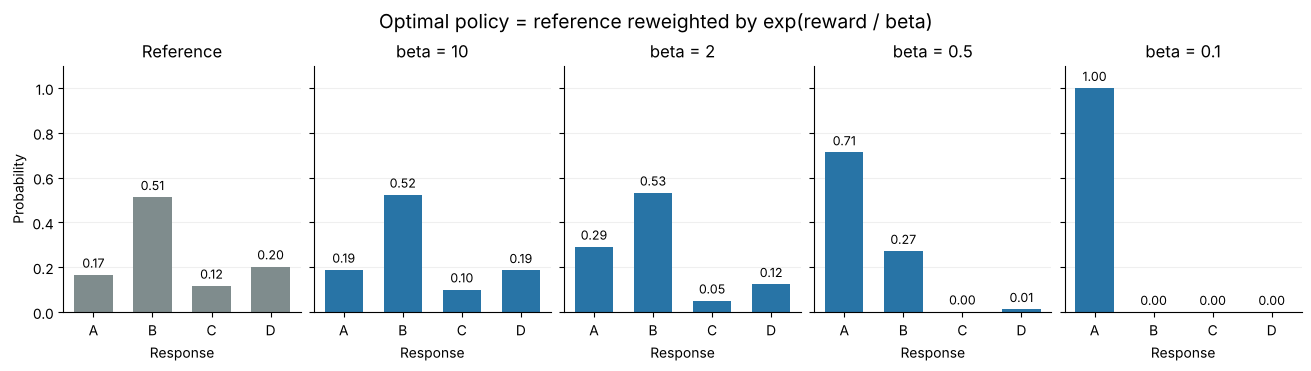

In [7]:
panels = [("Reference", example_ref)] + [(f"beta = {b:g}", optimal[b]) for b in BETAS]
fig, axes = plt.subplots(1, len(panels), figsize=(13, 3.6), sharey=True, constrained_layout=True)
for ax, (title, probs) in zip(axes, panels):
    color = "#7F8C8D" if title == "Reference" else "#2874A6"
    bars = ax.bar(LETTERS, probs.tolist(), color=color, width=0.65)
    ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)
    ax.set_title(title, fontsize=12)
    ax.set_ylim(0, 1.1)
    ax.set_xlabel("Response")
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Probability")
fig.suptitle("Optimal policy = reference reweighted by exp(reward / beta)", fontsize=14)
plt.show()

The reference puts the most probability on the long, polite response `B` and ignores accuracy. As $\beta$ decreases, probability moves toward `A`, which has the highest fitted reward, and the wrong answer `C` nearly disappears. At $\beta=10$, the optimal policy is still close to the reference; at $\beta=0.1$, it chooses `A` almost every time.

The second table shows the trade-off: as $\beta$ decreases, expected reward rises and the KL divergence from the reference grows. The check at $\beta=0.5$ confirms the derivation. The optimal policy has a higher objective than both the reference and the "always choose the best" policy, and its objective equals $\beta\ln Z(x)$. Always choosing `A` earns more reward, but it moves so far from the reference that the KL penalty outweighs the gain.

**Discuss:** the same $\pi^*$ comes from reward $r$ with penalty $\beta$ and from reward $2r$ with penalty $2\beta$. What does this say about how the size of the reward and the choice of $\beta$ interact?

## 4 · Direct preference optimization

The RLHF pipeline has two stages: fit a reward model (Section 2), then use reinforcement learning to approximate $\pi^*$ (Section 3). **Direct preference optimization (DPO)** fits the policy to the preferences in one step.

**Derive the DPO loss.** Start from the formula in Section 3, solved for the reward:

$$
r(x,y)=\beta\ln\frac{\pi^*(y\mid x)}{\pi_{\text{ref}}(y\mid x)}+\beta\ln Z(x).
$$

Substitute this into the Bradley–Terry model. The term $\beta\ln Z(x)$ is the same for both responses to a prompt, so it cancels in the difference:

$$
P(y_w\succ y_l\mid x)=\sigma\Big(\beta\ln\frac{\pi^*(y_w\mid x)}{\pi_{\text{ref}}(y_w\mid x)}-\beta\ln\frac{\pi^*(y_l\mid x)}{\pi_{\text{ref}}(y_l\mid x)}\Big).
$$

The preference probability is now written using the policy instead of the reward. DPO replaces $\pi^*$ with a trainable policy $\pi_\theta$ and minimizes the NLL of the observed preferences:

$$
L_{\text{DPO}}(\theta)=-\frac{1}{N}\sum_{i=1}^{N}\ln\sigma\Big(\beta\Big[\ln\frac{\pi_\theta(y_{w,i}\mid x_i)}{\pi_{\text{ref}}(y_{w,i}\mid x_i)}-\ln\frac{\pi_\theta(y_{l,i}\mid x_i)}{\pi_{\text{ref}}(y_{l,i}\mid x_i)}\Big]\Big).
$$

This is the Section 2 loss with the reward replaced by the **implicit reward** $\hat r_\theta(x,y)=\beta\ln\big(\pi_\theta(y\mid x)/\pi_{\text{ref}}(y\mid x)\big)$. The loss falls when the policy raises the preferred response's probability, relative to the reference, more than the other response's. No reward model and no sampling are needed: each update uses only the stored triples (prompt, preferred response, other response) and the log-probabilities of both responses under $\pi_\theta$ and $\pi_{\text{ref}}$.

**Our policy.** We let the policy reweight the reference using the features:

$$
\pi_\theta(y\mid x)=\frac{\pi_{\text{ref}}(y\mid x)\exp\big(\theta^\top\phi(x,y)\big)}{\sum_{y'}\pi_{\text{ref}}(y'\mid x)\exp\big(\theta^\top\phi(x,y')\big)}.
$$

At $\theta=0$, $\pi_\theta=\pi_{\text{ref}}$, so training starts at the reference and the loss starts at $\ln2$. For this family, $\ln(\pi_\theta/\pi_{\text{ref}})=\theta^\top\phi(x,y)$ minus a term that depends only on the prompt, and that term cancels in the loss. The implicit reward difference is therefore $\beta\theta^\top d_i$, and the DPO loss is exactly the reward-model loss with $\psi=\beta\theta$. Minimizing it should give $\beta\hat\theta\approx\hat\psi$, so the trained policy should match the RLHF optimum for the fitted reward. This exact match happens because our policy family contains $\pi^*$; for a language model, both methods only approximate it.

**Train with DPO.** We use $\beta=0.5$, start from $\theta=0$, and take 400 full-batch updates with Adam (learning rate 0.05) on the 600 training comparisons. Every 50 updates the code reports:

- the DPO loss on the training and test comparisons;
- **held-out pairwise accuracy** of the implicit reward;
- the **expected true utility** on the 100 test prompts, $\frac{1}{100}\sum_x\sum_y\pi_\theta(y\mid x)\,u(x,y)$, which we can compute only because we know $u$;
- the average KL divergence from the reference on the test prompts.

**What to expect:** the loss should fall, the expected true utility should rise from the reference's value, and the KL divergence should grow from zero.

In [8]:
DPO_BETA = 0.5


def policy_log_probs(theta, features):
    # pi_theta(y|x) is proportional to pi_ref(y|x) * exp(theta . phi(x,y))
    return torch.log_softmax(features @ (REF_WEIGHTS + theta), dim=-1)


def dpo_loss(theta, features, prefs, beta):
    rows = torch.arange(len(prefs["prompt"]))
    prompt_features = features[prefs["prompt"]]
    log_ratio = policy_log_probs(theta, prompt_features) - reference_log_probs(prompt_features)
    margin = beta * (log_ratio[rows, prefs["winner"]] - log_ratio[rows, prefs["loser"]])
    return -F.logsigmoid(margin).mean(), margin


@torch.no_grad()
def expected_utility(probs, features, weights=W_STAR):
    return (probs * utility(features, weights)).sum(dim=-1).mean().item()


test_ref_probs = reference_log_probs(test_features).exp()
theta = torch.zeros(len(FEATURES), requires_grad=True)
optimizer = torch.optim.Adam([theta], lr=0.05)
dpo_history = []

print(f"{'Update':<8}{'Train loss':>12}{'Test loss':>11}{'Held-out accuracy':>19}"
      f"{'Expected utility':>18}{'KL to ref':>11}")
print("-" * 79)
for update in range(0, 401):
    if update > 0:
        loss, _ = dpo_loss(theta, train_features, train_prefs, DPO_BETA)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    with torch.no_grad():
        train_loss, _ = dpo_loss(theta, train_features, train_prefs, DPO_BETA)
        test_loss, test_margin = dpo_loss(theta, test_features, test_prefs, DPO_BETA)
        probs = policy_log_probs(theta, test_features).exp()
        row = {
            "update": update, "train_loss": train_loss.item(), "test_loss": test_loss.item(),
            "accuracy": (test_margin > 0).float().mean().item(),
            "utility": expected_utility(probs, test_features),
            "kl": kl_divergence(probs, test_ref_probs).mean().item(),
        }
    dpo_history.append(row)
    if update % 50 == 0:
        print(f"{update:<8}{row['train_loss']:>12.4f}{row['test_loss']:>11.4f}{row['accuracy']:>18.1%}"
              f"{row['utility']:>18.3f}{row['kl']:>11.3f}")

theta_hat = theta.detach().clone()

Update    Train loss  Test loss  Held-out accuracy  Expected utility  KL to ref
-------------------------------------------------------------------------------
0             0.6931     0.6931              0.0%             2.465      0.000
50            0.5552     0.5634             73.3%             3.108      0.310
100           0.5206     0.5311             76.0%             3.287      0.495
150           0.5100     0.5239             75.2%             3.354      0.593
200           0.5068     0.5228             75.2%             3.385      0.648
250           0.5059     0.5231             75.2%             3.400      0.678
300           0.5057     0.5234             75.2%             3.407      0.693
350           0.5057     0.5237             75.0%             3.410      0.700
400           0.5057     0.5238             75.2%             3.412      0.703


At update 0 the policy equals the reference: the loss is $\ln2\approx0.693$, the KL divergence is 0, and the held-out accuracy is 0% because every implicit reward is exactly 0 (ties count as incorrect, as in Section 2). As training proceeds, the loss falls on both the training and the test comparisons, the expected true utility rises, and the policy moves away from the reference. The changes are largest early and level off as $\theta$ approaches its optimum. After about update 200, the test loss creeps up very slightly while the training loss falls a little further, a mild sign of fitting noise in the 600 training comparisons; the change is tiny compared with the initial drop. The held-out accuracy settles near the reward model's accuracy from Section 2, as the equivalence predicts.

**Compare the policies.** The next cell evaluates four policies on the 100 test prompts:

| Policy | What it is |
|---|---|
| Reference | $\pi_{\text{ref}}$ |
| DPO | $\pi_{\hat\theta}$, trained above |
| RLHF optimum, fitted reward | $\pi^*$ from Section 3 with $r_{\hat\psi}$ and $\beta=0.5$ |
| RLHF optimum, true utility | $\pi^*$ with $r=u$ and $\beta=0.5$: what we would get with unlimited comparisons |

The columns are the expected true utility; the probability of choosing each prompt's highest-utility response; the expected verbosity of the chosen response; the average KL divergence from the reference; and the **win rate against the reference**. The win rate is the probability that an annotator prefers a response sampled from the policy to an independently sampled response from the reference, using the true Bradley–Terry probabilities. When both samples are the same response, the annotator picks either with probability $1/2$, so the reference's win rate against itself is exactly 0.5.

The cell then checks the DPO-reward model equivalence, comparing $\beta\hat\theta$ with $\hat\psi$, and shows the DPO policy for the Celsius example.

In [9]:
@torch.no_grad()
def win_rate(probs, other_probs, features, weights=W_STAR, scale=1.0):
    u = utility(features, weights)
    prefer = preference_probability(u[:, :, None], u[:, None, :], scale)  # P(row response beats column)
    return (probs[:, :, None] * other_probs[:, None, :] * prefer).sum(dim=(1, 2)).mean().item()


@torch.no_grad()
def summarize_policy(probs, features):
    u = utility(features)
    return {
        "utility": expected_utility(probs, features),
        "p_best": probs.gather(1, u.argmax(dim=1, keepdim=True)).mean().item(),
        "verbosity": (probs * features[..., 2]).sum(dim=-1).mean().item(),
        "kl": kl_divergence(probs, reference_log_probs(features).exp()).mean().item(),
        "win_rate": win_rate(probs, reference_log_probs(features).exp(), features),
    }


with torch.no_grad():
    dpo_probs = policy_log_probs(theta_hat, test_features).exp()
    policies = {
        "Reference": test_ref_probs,
        "DPO": dpo_probs,
        "RLHF optimum, fitted reward": rlhf_optimal_probs(test_features, psi_hat, DPO_BETA),
        "RLHF optimum, true utility": rlhf_optimal_probs(test_features, W_STAR, DPO_BETA),
    }
summaries = {name: summarize_policy(probs, test_features) for name, probs in policies.items()}

print(f"TEST PROMPTS | beta = {DPO_BETA}")
print(f"{'Policy':<30}{'Utility':>9}{'P(best)':>9}{'Verbosity':>11}{'KL':>8}{'Win rate':>10}")
print("-" * 77)
for name, s in summaries.items():
    print(f"{name:<30}{s['utility']:>9.3f}{s['p_best']:>9.3f}{s['verbosity']:>11.3f}"
          f"{s['kl']:>8.3f}{s['win_rate']:>10.3f}")
best_average = test_u.max(dim=1).values.mean()
print(f"{'(Always the best response)':<30}{best_average:>9.3f}{1.0:>9.3f}")

gap = (dpo_probs - policies["RLHF optimum, fitted reward"]).abs().max()
print(f"\nLargest probability difference, DPO vs RLHF optimum with fitted reward: {gap:.4f}")
print(f"\n{'Feature':<14}{'True w*':>10}{'Fitted psi':>12}{'beta x theta':>14}")
print("-" * 50)
for k, name in enumerate(FEATURES):
    print(f"{name:<14}{W_STAR[k]:>10.2f}{psi_hat[k]:>12.3f}{DPO_BETA * theta_hat[k]:>14.3f}")

with torch.no_grad():
    example_dpo = policy_log_probs(theta_hat, EXAMPLE_FEATURES).exp()
print(f"\nCELSIUS EXAMPLE")
print(f"{'Response':<10}{'Utility u':>10}{'Reference':>11}{'DPO':>9}")
for k, letter in enumerate(LETTERS):
    print(f"{letter:<10}{example_utility[k]:>10.2f}{example_ref[k]:>11.3f}{example_dpo[k]:>9.3f}")

TEST PROMPTS | beta = 0.5
Policy                          Utility  P(best)  Verbosity      KL  Win rate
-----------------------------------------------------------------------------
Reference                         2.465    0.246      0.591   0.000     0.500
DPO                               3.412    0.697      0.479   0.703     0.674
RLHF optimum, fitted reward       3.412    0.697      0.479   0.705     0.674
RLHF optimum, true utility        3.400    0.687      0.491   0.675     0.672
(Always the best response)        3.592    1.000

Largest probability difference, DPO vs RLHF optimum with fitted reward: 0.0024

Feature          True w*  Fitted psi  beta x theta
--------------------------------------------------
relevance           2.00       1.829         1.826
accuracy            3.00       3.145         3.133
verbosity          -1.00      -1.183        -1.181
politeness          1.00       0.998         0.996

CELSIUS EXAMPLE
Response   Utility u  Reference      DPO
A           

DPO improves on the reference on every measure of quality: the expected true utility is higher, the policy chooses the best response more often, and its responses win against the reference's more often than not. It has also learned to prefer shorter responses than the verbosity-loving reference, because the annotators mildly penalize length. On the Celsius example, probability moves from the long response `B` to the short, correct response `A`.

DPO matches the RLHF optimum for the fitted reward almost exactly: $\beta\hat\theta$ agrees closely with $\hat\psi$, and the two policies' probabilities nearly coincide. DPO reached that policy without fitting a separate reward model and without sampling responses. Both are also close to the RLHF optimum under the true utility; the remaining differences come from estimation error in the 600 comparisons, not from the method.

The DPO policy does not always pick the best response. That is intentional: with $\beta=0.5$, the KL penalty keeps it near the reference, and the "always the best response" row is an upper limit that no policy at this $\beta$ is trying to reach.

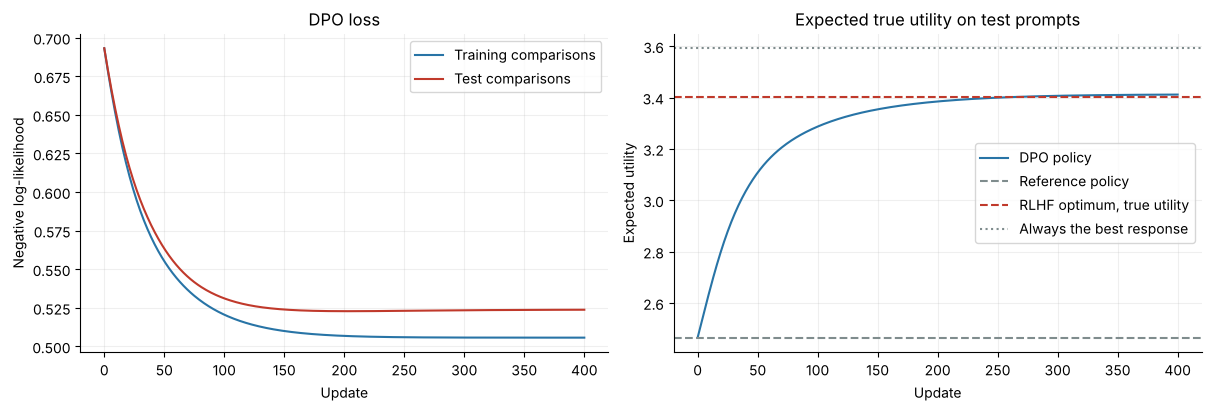

In [10]:
updates = [row["update"] for row in dpo_history]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)

axes[0].plot(updates, [row["train_loss"] for row in dpo_history], color="#2874A6", label="Training comparisons")
axes[0].plot(updates, [row["test_loss"] for row in dpo_history], color="#C0392B", label="Test comparisons")
axes[0].set_title("DPO loss")
axes[0].set_xlabel("Update")
axes[0].set_ylabel("Negative log-likelihood")
axes[0].legend()

axes[1].plot(updates, [row["utility"] for row in dpo_history], color="#2874A6", label="DPO policy")
axes[1].axhline(summaries["Reference"]["utility"], color="#7F8C8D", linestyle="--", label="Reference policy")
axes[1].axhline(summaries["RLHF optimum, true utility"]["utility"], color="#C0392B", linestyle="--",
                label="RLHF optimum, true utility")
axes[1].axhline(best_average, color="#7F8C8D", linestyle=":", label="Always the best response")
axes[1].set_title("Expected true utility on test prompts")
axes[1].set_xlabel("Update")
axes[1].set_ylabel("Expected utility")
axes[1].legend(loc="center right")

for ax in axes:
    ax.grid(alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)
plt.show()

The left panel shows the loss falling on both sets of comparisons, so the improvement carries over to prompts that were not used for training; the test loss flattens out after roughly 200 updates. The training and test losses are not directly comparable to each other: they average over different comparisons, some of which are harder to predict than others. In the right panel, the DPO policy's expected true utility starts at the reference's value and climbs to roughly the level of the RLHF optimum computed with the true utility. It stays below the "always the best response" line, as the KL penalty intends.

## 5 · Experiments: β, noise, and biased annotators

We now vary three ingredients and rerun DPO each time.

- **The penalty $\beta$.** Section 3 showed how $\beta$ trades reward against closeness to the reference.
- **Annotator consistency $\lambda$.** We scale the utility difference: $P(y_1\succ y_2\mid x)=\sigma\big(\lambda\,[u(x,y_1)-u(x,y_2)]\big)$. Small $\lambda$ means noisy annotators whose choices are close to coin flips; large $\lambda$ means annotators who almost always prefer the higher-utility response. So far, $\lambda=1$.
- **What annotators value.** We change the annotators' weights $w$ while still evaluating the policy with the true utility $u$ (weights $w^*$). For example, annotators might reward length because long answers *look* thorough.

**What the code does.** `run_preference_experiment` simulates a fresh set of 600 training comparisons on the same training prompts using the chosen annotators, trains DPO from the reference (600 full-batch Adam updates, learning rate 0.5, enough to converge for every setting below), and evaluates the trained policy on the test prompts with the true utility. Each setting shows the same pairs and uses the same uniform draws, so differences between rows come from the settings. Because these comparisons are new, the default row differs slightly from Section 4.

**Predict before running:** for each row below, will the policy's expected verbosity and its KL divergence from the reference be higher or lower than in the default row? Which row will have the lowest expected true utility?

In [11]:
def run_preference_experiment(beta=0.5, scale=1.0, annotator_weights=W_STAR, seed=SEED + 1):
    generator = torch.Generator().manual_seed(seed)
    annotator_weights = torch.as_tensor(annotator_weights, dtype=torch.float32)
    prefs = simulate_preferences(train_features, COMPARISONS_PER_PROMPT, generator,
                                 weights=annotator_weights, scale=scale)
    theta = torch.zeros(len(FEATURES), requires_grad=True)
    optimizer = torch.optim.Adam([theta], lr=0.5)
    for _ in range(600):
        loss, _ = dpo_loss(theta, train_features, prefs, beta)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    with torch.no_grad():
        probs = policy_log_probs(theta, test_features).exp()
    result = summarize_policy(probs, test_features)
    # Win rate as judged by these annotators instead of by the true utility.
    result["annotator_win_rate"] = win_rate(probs, test_ref_probs, test_features, annotator_weights, scale)
    return result


def verbosity_loving(weight):
    return torch.tensor([2.0, 3.0, weight, 1.0])


SETTINGS = [
    ("Default", dict()),
    ("Small beta = 0.1", dict(beta=0.1)),
    ("Large beta = 2", dict(beta=2.0)),
    ("Noisy annotators, lambda = 0.25", dict(scale=0.25)),
    ("Consistent annotators, lambda = 4", dict(scale=4.0)),
    ("Annotators like length (+2)", dict(annotator_weights=verbosity_loving(2.0))),
]

experiment_results = {}
print(f"{'Setting':<35}{'Utility':>9}{'Verbosity':>11}{'KL':>8}{'Win rate':>10}")
print("-" * 73)
reference_summary = summaries["Reference"]
print(f"{'Reference policy':<35}{reference_summary['utility']:>9.3f}"
      f"{reference_summary['verbosity']:>11.3f}{0.0:>8.3f}{0.5:>10.3f}")
for name, kwargs in SETTINGS:
    result = run_preference_experiment(**kwargs)
    experiment_results[name] = result
    print(f"{name:<35}{result['utility']:>9.3f}{result['verbosity']:>11.3f}"
          f"{result['kl']:>8.3f}{result['win_rate']:>10.3f}")

length = experiment_results["Annotators like length (+2)"]
print("-" * 73)
print("Policy trained on length-loving annotators, win rate against the reference:")
print(f"  judged by those annotators: {length['annotator_win_rate']:.3f}")
print(f"  judged by the true utility: {length['win_rate']:.3f}")

Setting                              Utility  Verbosity      KL  Win rate
-------------------------------------------------------------------------
Reference policy                       2.465      0.591   0.000     0.500
Default                                3.416      0.478   0.718     0.675
Small beta = 0.1                       3.580      0.427   1.355     0.709
Large beta = 2                         2.868      0.553   0.104     0.572
Noisy annotators, lambda = 0.25        2.883      0.517   0.139     0.575
Consistent annotators, lambda = 4      3.582      0.430   1.326     0.709
Annotators like length (+2)            3.152      0.651   0.587     0.624
-------------------------------------------------------------------------
Policy trained on length-loving annotators, win rate against the reference:
  judged by those annotators: 0.656
  judged by the true utility: 0.624


Read the rows against the default (utility and win rate use the true utility in every row):

- **β.** A small $\beta$ lets the policy move far from the reference: compared with the default, the KL divergence roughly doubles, verbosity falls, and expected utility rises. A large $\beta$ keeps the policy close to the reference, so it gains much less.
- **Annotator consistency.** Noisy annotators ($\lambda=0.25$) give a weak signal: the fitted implicit reward is small, so the policy stays close to the reference. Consistent annotators ($\lambda=4$) give large reward differences, and the policy moves much further. Compare these rows with the $\beta$ rows. The optimum $\pi^*$ depends on the reward only through $\lambda u/\beta$, so $\lambda=0.25$ with $\beta=0.5$ targets the same policy as $\lambda=1$ with $\beta=2$, and $\lambda=4$ with $\beta=0.5$ is close to $\lambda=1$ with $\beta=0.1$. The matching rows are similar but not identical: the annotators' choice probabilities differ, so the same uniform draws produce somewhat different choices, and the estimation errors differ. This is the point of Section 3's **Discuss** question.
- **Length-loving annotators.** The policy learns what the annotators reward: its expected verbosity rises above the default and even above the verbose reference. It still improves on the reference, because the annotators also value accuracy and relevance, but its true utility is clearly lower than the default row's. The final lines show the problem: judged by the same annotators who produced the training data, the policy looks better than it does under the true utility.

The lowest expected true utility comes from the large-$\beta$ and noisy-annotator rows, where the policy barely moves from the reference, not from the biased annotators. Bias makes the policy move in a partly wrong direction; a weak signal or a strong penalty keeps it from moving much at all.

**Discuss:** this is a simple form of **reward hacking**. The policy optimizes the preferences it was trained on. If those preferences contain a bias, a better optimizer exploits the bias more. How could you detect this without knowing the true utility? (One idea: track simple properties of the responses, such as length, before and after training, and collect comparisons from annotators instructed to ignore length.)

**Try it:** change `YOUR_BETA`, `YOUR_LAMBDA` (annotator consistency $\lambda$), and `YOUR_WEIGHTS` (relevance, accuracy, verbosity, politeness), predict how the expected utility, verbosity, and KL divergence will move compared with the default, then run the cell. Some ideas: annotators who ignore accuracy (`(2.0, 0.0, -1.0, 1.0)`); annotators who care only about politeness; a very large `YOUR_BETA`. Each run takes a few seconds.

In [12]:
YOUR_BETA = 0.5
YOUR_LAMBDA = 1.0
YOUR_WEIGHTS = (2.0, 3.0, -1.0, 1.0)  # relevance, accuracy, verbosity, politeness

if YOUR_BETA <= 0 or YOUR_LAMBDA <= 0 or len(YOUR_WEIGHTS) != 4:
    raise ValueError("Use a positive beta, a positive lambda, and four weights.")

yours = run_preference_experiment(beta=YOUR_BETA, scale=YOUR_LAMBDA, annotator_weights=YOUR_WEIGHTS)
default = experiment_results["Default"]
print(f"{'Policy':<22}{'Utility':>9}{'Verbosity':>11}{'KL':>8}{'Win rate':>10}{'Annotators win rate':>21}")
print("-" * 81)
print(f"{'Reference':<22}{reference_summary['utility']:>9.3f}{reference_summary['verbosity']:>11.3f}"
      f"{0.0:>8.3f}{0.5:>10.3f}{0.5:>21.3f}")
for name, r in [("Default DPO", default), ("Your DPO", yours)]:
    print(f"{name:<22}{r['utility']:>9.3f}{r['verbosity']:>11.3f}{r['kl']:>8.3f}"
          f"{r['win_rate']:>10.3f}{r['annotator_win_rate']:>21.3f}")

Policy                  Utility  Verbosity      KL  Win rate  Annotators win rate
---------------------------------------------------------------------------------
Reference                 2.465      0.591   0.000     0.500                0.500
Default DPO               3.416      0.478   0.718     0.675                0.675
Your DPO                  3.416      0.478   0.718     0.675                0.675


### How this maps to a language model

- **Responses are sampled texts.** Instead of four fixed candidates with features, a language model can produce any text. Preference datasets are built by sampling two (or more) responses per prompt, often from the supervised fine-tuned model, and asking people which they prefer.
- **Log-probabilities are sums over tokens.** As in Weeks 1–3, $\ln\pi_\theta(y\mid x)=\sum_{t}\ln\pi_\theta(y_t\mid x,y_{<t})$, summed over the response tokens. DPO needs four such numbers per comparison: the log-probabilities of the chosen and rejected responses under the policy and under the frozen reference model.
- **The reference is a copy of the starting model.** It is usually the supervised fine-tuned model from Week 2, kept fixed during training.
- **RLHF versus DPO.** RLHF fits a reward model (often a language model with a scalar output head, trained with the Bradley–Terry loss from Section 2) and then optimizes the policy against it with reinforcement learning and a KL penalty. DPO skips the reward model and optimizes the policy directly on the comparisons. For a language model, neither recovers $\pi^*$ exactly, and the two can behave differently in practice.

Hugging Face's TRL library implements DPO. Its training data are (prompt, chosen, rejected) triples. A configuration looks like this (not run here):

```python
from datasets import Dataset
from trl import DPOConfig, DPOTrainer

train_dataset = Dataset.from_list([
    {"prompt": "How do I convert Celsius to Fahrenheit?",
     "chosen": " Multiply by 9/5 and add 32.",
     "rejected": " Add 32, then multiply by 5/9."},
    # ... many more comparisons
])

trainer = DPOTrainer(
    model=model,              # the policy being trained, e.g., a supervised fine-tuned model
    ref_model=ref_model,      # frozen copy of the starting model
    args=DPOConfig(beta=0.1, output_dir="dpo-model"),
    train_dataset=train_dataset,
    processing_class=tokenizer,
)
trainer.train()
```

Here `beta` plays the same role as $\beta$ in this notebook. If `ref_model` is omitted, TRL uses a copy of the starting model as the reference.

## Recap

We learned a policy from comparisons instead of from a verifier:

**Prompt → two responses → human preference → Bradley–Terry likelihood → reward model or DPO loss → policy closer to what people prefer**

The Bradley–Terry model turns a hidden utility into preference probabilities. Fitting it to comparisons is logistic regression on feature differences, and it gives a reward model. RLHF looks for the policy that maximizes reward minus $\beta$ times the KL divergence from a reference; that optimum reweights the reference by $\exp(r/\beta)$. DPO uses that formula to write the Bradley–Terry likelihood in terms of the policy itself, so it trains the policy directly on the comparisons. A policy can only be as good as the preferences it learns from: biased annotators produce a biased policy.

### Check your understanding

1. Why does the reward model have no intercept, and why can we still estimate the size of its weights?
2. Even the true utility predicted only about three-quarters of the held-out preferences. Does this mean the Bradley–Terry model is wrong here?
3. What does the RLHF optimum $\pi^*$ look like when $\beta$ is very large? When $\beta$ is very small?
4. In the DPO loss, why does the normalizing constant $Z(x)$ disappear?
5. If annotators systematically prefer longer responses, what will DPO learn, and why can't a smaller $\beta$ fix it?

<details><summary>Answers · open after discussing</summary>

1. Only reward differences enter the Bradley–Terry probabilities, so adding a constant to every reward changes nothing and the data cannot determine it. The scale is different: multiplying all weights by 2 changes $\sigma(\psi^\top d)$, so the logistic link pins down the size of the weights relative to the annotators' noise.
2. No. The model says that choices are random, with probability $\sigma(u_1-u_2)$. When two responses have similar utilities, annotators often choose the lower-utility one. Accuracy near the expected accuracy $\sigma(|u_1-u_2|)$, averaged over pairs, is what the model predicts.
3. Large $\beta$: $\exp(r/\beta)$ is nearly constant, so $\pi^*\approx\pi_{\text{ref}}$. Small $\beta$: nearly all probability goes to the highest-reward response (among those the reference can produce).
4. $Z(x)$ depends only on the prompt. Both responses in a comparison share the same prompt, so $\beta\ln Z(x)$ appears in both implicit rewards and cancels in their difference.
5. It learns to favor longer responses, because it optimizes the preferences it was given. A smaller $\beta$ only lets the policy follow those preferences more closely, bias included; it cannot remove a bias that is in the data. Fixing it requires better preference data or an explicit correction for length.

</details>

### Next week: uncertainty without retraining

So far, we have changed a model's weights to improve its answers or its stated confidence. Often we cannot retrain the model and must work with the probabilities it already produces. Next week, we estimate a fixed model's uncertainty from its outputs: agreement among sampled answers, temperature scaling to correct overconfidence, and conformal prediction sets that contain the correct answer with a guaranteed probability on average over questions.

## References and further reading

- [Bradley and Terry (1952): Rank analysis of incomplete block designs](https://doi.org/10.2307/2334029): the paired-comparison model.
- [Ouyang et al. (2022): Training language models to follow instructions with human feedback](https://arxiv.org/abs/2203.02155): reward models and RLHF.
- [Rafailov et al. (2023): Direct preference optimization](https://arxiv.org/abs/2305.18290): the DPO objective.
- [Hugging Face TRL: DPO Trainer](https://huggingface.co/docs/trl/dpo_trainer): DPO for language models in practice.